### Installing required libraries

In [186]:
# Install required libraries
!pip install seaborn missingno xgboost catboost regex scikit-learn pandas numpy imblearn lightgbm polars


### Importing all libraries 

In [187]:
# Core libraries
import pandas as pd
import numpy as np
import csv
import re

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import resample

# Model selection
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

# Models
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import xgboost as xgb

# Metrics
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    make_scorer
)


### Import additional items as needed...

In [188]:
# Model selection utilities
from sklearn.model_selection import (
    KFold,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score
)

# Preprocessing & pipelines
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import make_pipeline

# Models & balancing
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE

# Metrics (only those not already imported in Script 2)
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# Plotly visualization
import plotly
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

# Suppress warnings
import warnings
warnings.filterwarnings("ignore")


### Loading CSV data 

In [189]:
diabetes = pd.read_csv('raw/diabetic_data.csv')

# CLEANING AND TRANSFORMING THE DATASET

In [190]:
print(diabetes.columns)

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')


In [191]:
for g in diabetes['gender'].unique():
    col = f"Gender_{g}"
    diabetes[col] = (diabetes['gender'] == g).astype(int)


In [192]:
#@title AGE ENCODING
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [193]:
# Mapping each admission_type_id to a category name
admission_type_map = {
    1: "emergency",
    2: "urgent",
    3: "elective",
    4: "newborn",
    5: "notavailable",
    6: "null",
    7: "trauma",
    8: "notmapped"
}

# Convert ID → category name
diabetes["admission_type"] = diabetes["admission_type_id"].map(admission_type_map)

# One-hot encode into separate binary columns (each column = 0 or 1)
admission_dummies = pd.get_dummies(
    diabetes["admission_type"],
    prefix="admission"
).astype(int)

# Add new columns to the dataframe
diabetes = pd.concat([diabetes, admission_dummies], axis=1)


In [194]:
# Mapping discharge_disposition_id → category name
discharge_disposition_map = {
    1: "home",
    2: "short_term_hospital",
    3: "snf",
    4: "icf",
    5: "other_inpatient",
    6: "home_health",
    7: "left_ama",
    8: "home_iv_care",
    9: "admitted_this_hospital",
    10: "neonate_another_hospital",
    11: "expired",
    12: "still_patient",
    13: "hospice_home",
    14: "hospice_facility",
    15: "swing_bed",
    16: "outpatient_other_institution",
    17: "outpatient_this_institution",
    18: "null",
    19: "expired_home_medicaid",
    20: "expired_facility_medicaid",
    21: "expired_unknown_medicaid",
    22: "rehab_facility",
    23: "long_term_care_hospital",
    24: "medicaid_nursing_facility",
    25: "not_mapped",
    27: "federal_healthcare_facility",
    28: "psychiatric_hospital",
    29: "critical_access_hospital",
    30: "other_healthcare_institution"
}

# Convert ID → category name
diabetes["discharge_type"] = diabetes["discharge_disposition_id"].map(discharge_disposition_map)

# One-hot encode into separate binary columns (each column = 0 or 1)
discharge_dummies = pd.get_dummies(
    diabetes["discharge_type"],
    prefix="discharge"
).astype(int)

# Add new columns to the dataframe
diabetes = pd.concat([diabetes, discharge_dummies], axis=1)


In [195]:
def icd_to_chapter(code):
    # Convert to string for prefix checks
    code_str = str(code).strip().upper()

    # Supplemental codes
    if code_str.startswith('V'):
        return "V-codes: Factors Influencing Health Status"
    if code_str.startswith('E'):
        return "E-codes: External Causes of Injury"

    # Try converting numeric codes
    try:
        code_num = float(code)
    except:
        return "Unmapped"

    # ICD-9 numeric ranges
    if 1 <= code_num <= 139:
        return "Infectious and Parasitic Diseases"
    elif 140 <= code_num <= 239:
        return "Neoplasms"
    elif 240 <= code_num <= 279:
        return "Endocrine/Metabolic"
    elif 280 <= code_num <= 289:
        return "Blood Diseases"
    elif 290 <= code_num <= 319:
        return "Mental Disorders"
    elif 320 <= code_num <= 389:
        return "Nervous System"
    elif 390 <= code_num <= 459:
        return "Circulatory System"
    elif 460 <= code_num <= 519:
        return "Respiratory System"
    elif 520 <= code_num <= 579:
        return "Digestive System"
    elif 580 <= code_num <= 629:
        return "Genitourinary System"
    elif 630 <= code_num <= 679:
        return "Pregnancy/Childbirth"
    elif 680 <= code_num <= 709:
        return "Skin/Subcutaneous"
    elif 710 <= code_num <= 739:
        return "Musculoskeletal"
    elif 740 <= code_num <= 759:
        return "Congenital Anomalies"
    elif 760 <= code_num <= 779:
        return "Perinatal Conditions"
    elif 780 <= code_num <= 799:
        return "Symptoms/Ill-defined"
    elif 800 <= code_num <= 999:
        return "Injury/Poisoning"
    else:
        return "Unmapped"


In [196]:
for col in ["diag_1", "diag_2", "diag_3"]:
    diabetes[col + "_chapter"] = diabetes[col].apply(icd_to_chapter)


In [197]:
# Mapping ICD chapter names to clean category labels
diag_chapter_map = {
    "Endocrine/Metabolic": "endocrine_metabolic",
    "Circulatory System": "circulatory",
    "Respiratory System": "respiratory",
    "Neoplasms": "neoplasms",
    "Infectious and Parasitic Diseases": "infectious_parasitic",
    "Injury/Poisoning": "injury_poisoning",
    "Genitourinary System": "genitourinary",
    "Nervous System": "nervous_system",
    "Blood Diseases": "blood_diseases",
    "Mental Disorders": "mental_disorders",
    "Symptoms/Ill-defined": "symptoms_ill_defined",
    "Skin/Subcutaneous": "skin_subcutaneous",
    "Musculoskeletal": "musculoskeletal",
    "Digestive System": "digestive",
    "Pregnancy/Childbirth": "pregnancy_childbirth",
    "Congenital Anomalies": "congenital_anomalies",

    # Supplemental code labels
    "V-codes: Factors Influencing Health Status": "v_codes",
    "E-codes: External Causes of Injury": "e_codes",

    # Unmapped label
    "Unmapped": "unmapped"
}

# Apply mapping to each diagnosis column
for col in ["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]:
    diabetes[col] = diabetes[col].map(diag_chapter_map)

# One-hot encode all three diagnosis chapter columns
diag_dummies = pd.get_dummies(
    diabetes[["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]],
    prefix=["diag1", "diag2", "diag3"]
).astype(int)

# Add new columns to the dataframe
diabetes = pd.concat([diabetes, diag_dummies], axis=1)


In [198]:
#@title DIABEST MEDICATION ENCODING
# replacing No with 0 and Yes with 1 for if the patient has diabetic medications or not
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(
    lambda x: 1 if str(x).strip().lower() == "yes" else 0
)

In [199]:
# Encode insulin usage: Yes → 1, No → 0
diabetes['insulin'] = diabetes['insulin'].apply(
    lambda x: 1 if str(x).strip().lower() == "yes" else 0
)

In [200]:
#@title READMITTED ENCODING
# Created indicator column for readmission within 30 days
# lessthan30 = 1 if readmitted is "<30", else 0

diabetes['lessthan30'] = (diabetes['readmitted'] == '<30').astype(int)

In [201]:
#@title RACE ENCODING
# Replace '?' with 'Unknown'
diabetes['race'] = diabetes['race'].replace('?', 'Unknown')

# Create binary columns for each race category
for race in diabetes['race'].unique():
    col_name = f"Race_{race}"
    diabetes[col_name] = (diabetes['race'] == race).astype(int)


In [202]:
import random

# -----------------------------
# 1. Conversion functions
# -----------------------------

def convert_weight(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        return random.randint(201, 250)

    if '-' in value:
        clean = value.replace('(', '').replace(')', '')
        low, high = clean.split('-')
        return int(high)

    return None


def convert_glucose(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        threshold = int(value[1:])
        return random.randint(threshold + 1, threshold + 50)

    if value == "Norm":
        return random.randint(70, 99)

    return None


def convert_a1c(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        threshold = float(value[1:])
        return round(random.uniform(threshold + 0.1, threshold + 1.0), 1)

    if value == "Norm":
        return round(random.uniform(4.0, 5.6), 1)

    return None


# -----------------------------
# 2. Apply conversions
# -----------------------------

diabetes['weight_num'] = diabetes['weight'].apply(convert_weight)
diabetes['max_glu_serum_num'] = diabetes['max_glu_serum'].apply(convert_glucose)
diabetes['A1Cresult_num'] = diabetes['A1Cresult'].apply(convert_a1c)


# -----------------------------
# 3. RANDOM IMPUTATION for NaN
# -----------------------------

# Random weight between 25 and 250
diabetes['weight_num'] = diabetes['weight_num'].apply(
    lambda x: x if not pd.isna(x) else random.randint(25, 250)
)

# Random glucose between 70 and 350
diabetes['max_glu_serum_num'] = diabetes['max_glu_serum_num'].apply(
    lambda x: x if not pd.isna(x) else random.randint(70, 350)
)

# Random A1C between 4.0 and 10.0
diabetes['A1Cresult_num'] = diabetes['A1Cresult_num'].apply(
    lambda x: x if not pd.isna(x) else round(random.uniform(4.0, 10.0), 1)
)


# -----------------------------
# 4. Verify no missing values
# -----------------------------

print(diabetes[['weight_num','max_glu_serum_num','A1Cresult_num']].isna().sum())


weight_num           0
max_glu_serum_num    0
A1Cresult_num        0
dtype: int64


In [203]:
#@title drop 1 intial columns
# Dropping unnecessary columns due to high missing values and low relevance
cleandiabetes = diabetes.drop([
    'encounter_id', 'patient_nbr', 'race', 'gender', 'weight', 'max_glu_serum', 'A1Cresult',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'payer_code', 'medical_specialty', 'diag_1','discharge_type','admission_type',
       'diag_2', 'diag_3', 'admission_type_id', 'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter',
       'discharge_disposition_id', 'admission_source_id',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'readmitted'
], axis=1)

In [204]:
for col in cleandiabetes.columns:
    print(col)

age
time_in_hospital
num_lab_procedures
num_procedures
num_medications
number_outpatient
number_emergency
number_inpatient
number_diagnoses
insulin
diabetesMed
Gender_Female
Gender_Male
Gender_Unknown/Invalid
admission_elective
admission_emergency
admission_newborn
admission_notavailable
admission_notmapped
admission_null
admission_trauma
admission_urgent
discharge_admitted_this_hospital
discharge_expired
discharge_expired_facility_medicaid
discharge_expired_home_medicaid
discharge_federal_healthcare_facility
discharge_home
discharge_home_health
discharge_home_iv_care
discharge_hospice_facility
discharge_hospice_home
discharge_icf
discharge_left_ama
discharge_long_term_care_hospital
discharge_medicaid_nursing_facility
discharge_neonate_another_hospital
discharge_not_mapped
discharge_null
discharge_other_inpatient
discharge_outpatient_other_institution
discharge_outpatient_this_institution
discharge_psychiatric_hospital
discharge_rehab_facility
discharge_short_term_hospital
discharge_sn

In [205]:
numerical = ['time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_emergency',
    'number_outpatient',
    'number_inpatient',
    'number_diagnoses','weight_num', 'max_glu_serum_num', 'A1Cresult_num' ]

### MISSING DATA

In [206]:
def missing(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1,
                               keys=['Missing_Number', 'Missing_Percent'])
    return missing_values

In [207]:
#save cleaned dataset to csv
cleandiabetes.to_csv('raw/cleaned_diabetes.csv', index=False)

In [208]:
print("Missing Data in Sub1:")
display(missing(cleandiabetes))



Missing Data in Sub1:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
...,...,...
Race_Asian,0,0.0
Race_Hispanic,0,0.0
weight_num,0,0.0
max_glu_serum_num,0,0.0


### CORRELATION

In [209]:
#@title Correlation Matrices
print("Correlation Matrix for Sub1")
display(cleandiabetes[numerical].corr())

Correlation Matrix for Sub1


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_emergency,number_outpatient,number_inpatient,number_diagnoses,weight_num,max_glu_serum_num,A1Cresult_num
time_in_hospital,1.000000,0.318450,0.191472,0.466135,-0.009681,-0.008916,0.073623,0.220186,-0.003451,0.008300,0.001171
num_lab_procedures,0.318450,1.000000,0.058066,0.268161,-0.002279,-0.007602,0.039231,0.152773,-0.011049,0.022231,0.011817
num_procedures,0.191472,0.058066,1.000000,0.385767,-0.038179,-0.024819,-0.066236,0.073734,-0.003664,0.009486,0.003136
num_medications,0.466135,0.268161,0.385767,1.000000,0.013180,0.045197,0.064194,0.261526,-0.003979,0.009269,0.001820
number_emergency,-0.009681,-0.002279,-0.038179,0.013180,1.000000,0.091459,0.266559,0.055539,-0.002677,0.010899,-0.003165
number_outpatient,-0.008916,-0.007602,-0.024819,0.045197,0.091459,1.000000,0.107338,0.094152,-0.007134,-0.003511,-0.001155
number_inpatient,0.073623,0.039231,-0.066236,0.064194,0.266559,0.107338,1.000000,0.104710,-0.000931,-0.000591,-0.001664
number_diagnoses,0.220186,0.152773,0.073734,0.261526,0.055539,0.094152,0.104710,1.000000,-0.006691,0.002046,-0.017988
weight_num,-0.003451,-0.011049,-0.003664,-0.003979,-0.002677,-0.007134,-0.000931,-0.006691,1.000000,-0.002895,-0.004779
max_glu_serum_num,0.008300,0.022231,0.009486,0.009269,0.010899,-0.003511,-0.000591,0.002046,-0.002895,1.000000,0.000758


In [210]:
print("Correlation for lessthan30 grouped by lessthan30")
display(cleandiabetes.groupby('lessthan30')[numerical].corr())


Correlation for lessthan30 grouped by lessthan30


time_in_hospital  num_lab_procedures  \
lessthan30                                                            
0          time_in_hospital            1.000000            0.317989   
           num_lab_procedures          0.317989            1.000000   
           num_procedures              0.184408            0.052895   
           num_medications             0.463444            0.263560   
           number_emergency           -0.003926            0.004755   
           number_outpatient          -0.008024           -0.009675   
           number_inpatient            0.081368            0.044145   
           number_diagnoses            0.222780            0.153492   
           weight_num                 -0.002882           -0.010260   
           max_glu_serum_num           0.006375            0.023261   
           A1Cresult_num              -0.000913            0.012316   
1          time_in_hospital            1.000000            0.317655   
           num_lab_procedures          0.317655            1.000000   
           num_procedures              0.256572            0.104734   
           num_medications             0.479381            0.300945   
           number_emergency           -0.054951           -0.046064   
           number_outpatient          -0.022948            0.005296   
           number_inpatient            0.011970            0.004974   
           number_diagnoses            0.182704            0.138825   
           weight_num                 -0.006536           -0.016861   
           max_glu_serum_num           0.024276            0.014383   
           A1Cresult_num               0.018121            0.008113   

                               num_procedures  num_medications  \
lessthan30                                                       
0          time_in_hospital          0.184408         0.463444   
           num_lab_procedures        0.052895         0.263560   
           num_procedures            1.000000         0.385410   
           num_medications           0.385410         1.000000   
           number_emergency         -0.036945         0.017058   
           number_outpatient        -0.023123         0.044063   
           number_inpatient         -0.063114         0.066989   
           number_diagnoses          0.071852         0.261229   
           weight_num               -0.003414        -0.003395   
           max_glu_serum_num         0.011021         0.009837   
           A1Cresult_num             0.003560        -0.000896   
1          time_in_hospital          0.256572         0.479381   
           num_lab_procedures        0.104734         0.300945   
           num_procedures            1.000000         0.396435   
           num_medications           0.396435         1.000000   
           number_emergency         -0.044692        -0.019015   
           number_outpatient        -0.036554         0.048016   
           number_inpatient         -0.084559         0.028102   
           number_diagnoses          0.098215         0.251496   
           weight_num               -0.006186        -0.007436   
           max_glu_serum_num        -0.003502         0.005650   
           A1Cresult_num            -0.000576         0.024065   

                               number_emergency  number_outpatient  \
lessthan30                                                           
0          time_in_hospital           -0.003926          -0.008024   
           num_lab_procedures          0.004755          -0.009675   
           num_procedures             -0.036945          -0.023123   
           num_medications             0.017058           0.044063   
           number_emergency            1.000000           0.091215   
           number_outpatient           0.091215           1.000000   
           number_inpatient            0.241279           0.106598   
           number_diagnoses            0.056901           0.093659   
           weight_num                 -0.

In [211]:
#@title Reusable Correlation Heatmaps
def plot_corr_heatmap(df, numerical, title):
    """
    Plots a lower‑triangle correlation heatmap for a given dataframe.
    """
    corr_matrix = df[numerical].corr()

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        center=0,
        square=True,
        linewidths=0.5,
        fmt='.2f',
        mask=mask
    )

    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()


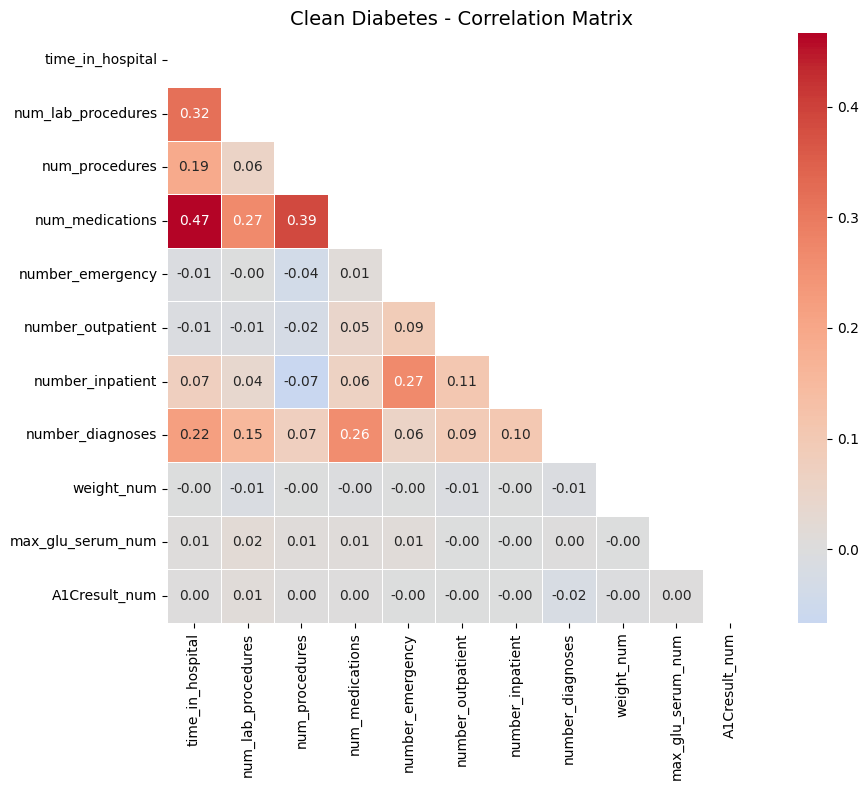

In [212]:
plot_corr_heatmap(cleandiabetes, numerical, "Clean Diabetes - Correlation Matrix")


## Breaking the data up into Train & Test

In [213]:
#@title Setting Up Data for Modeling 
#Uses the cleandiabetes dataset for modeling.
DataTesting = cleandiabetes.copy() #change it to sub2 or Sub3 to test each dataset

In [214]:
# Step 1: Split cleandiabetes into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    DataTesting,
    test_size=0.30,        # 30% goes to temp (valid + test)
    random_state=42,       # ensures reproducibility
    shuffle=True           # shuffles before splitting
)


# Step 2: Split Temp into Validation (15%) and Test (15%)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,        # half of temp = 15% of total
    random_state=42,
    shuffle=True
)

# Step 3: Reset indexes for cleanliness
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


# Step 4: Just Making Sure Check
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(valid_df) + len(test_df))


Train size: 71236
Validation size: 15265
Test size: 15265
Total: 101766


In [215]:
DataTesting.lessthan30.value_counts()

lessthan30
0    90409
1    11357
Name: count, dtype: int64

In [216]:
train_df.lessthan30.value_counts()

lessthan30
0    63304
1     7932
Name: count, dtype: int64

In [217]:
valid_df.lessthan30.value_counts()

lessthan30
0    13500
1     1765
Name: count, dtype: int64

In [218]:
test_df.lessthan30.value_counts()

lessthan30
0    13605
1     1660
Name: count, dtype: int64

## Ways to Fix/Treat the Imbalance in the Data
Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

#### 1. RANDOM OVERSAMPLING: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.

In [219]:
def balance_random_oversample(df, target='lessthan30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_pos_over = resample(
        df_pos,
        replace=True,
        n_samples=len(df_neg),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_neg, df_pos_over])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 2. SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.

In [220]:
def balance_smote(df, target='lessthan30', random_state=42):
    X = df.drop(columns=[target])
    y = df[target]

    sm = SMOTE(random_state=random_state)
    X_res, y_res = sm.fit_resample(X, y)

    df_bal = pd.concat(
        [pd.DataFrame(X_res, columns=X.columns),
         pd.Series(y_res, name=target)],
        axis=1
    )

    return df_bal

#### 3. RANDOM UNDERSAMPLING
Random Undersampling reduces the size of the majority class by randomly removing samples until it matches the minority class count. This creates a balanced dataset without generating synthetic data.

In [221]:
def balance_random_undersample(df, target='lessthan30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_neg_under = df_neg.sample(
        n=len(df_pos),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_pos, df_neg_under])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 4. SMOTEENN


In [222]:
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE

def apply_smoteenn(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTEENN hybrid resampling:
    - SMOTE oversamples the minority class
    - ENN removes noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_enn = SMOTEENN(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_enn.fit_resample(X, y)
    return X_resampled, y_resampled

#### 5. SMOTETOMEK

In [223]:
from imblearn.combine import SMOTETomek

def apply_smotetomek(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTETomek hybrid resampling:
    - SMOTE oversamples the minority class
    - Tomek Links remove borderline/noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_tomek = SMOTETomek(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_tomek.fit_resample(X, y)
    return X_resampled, y_resampled


#### Prevalence Caculation Function

In [224]:
def calc_prevalence(y_actual):
    """
    Calculate the prevalence (ratio of positive class = 1)
    in a binary target array or Series.
    """
    y_actual = pd.Series(y_actual)
    return y_actual.mean()

<h2 style="color:#e63946;">CHANGE THE IMBALANCE TECHNIQUE HERE</h2>
“Remove the # to activate a specific technique."


In [225]:
# 1. Split train_df into X and y
X_train = train_df.drop(columns=["lessthan30"])
y_train = train_df["lessthan30"]

# 2. Apply SMOTEENN
X_bal, y_bal = apply_smoteenn(X_train, y_train)

# 3. Combine back into a single DataFrame (optional)
train_balanced = X_bal.copy()
train_balanced["lessthan30"] = y_bal

# 4. Check prevalence
print(
    "Train balanced prevalence (n = %d): %.3f" %
    (len(train_balanced), calc_prevalence(train_balanced['lessthan30']))
)


Train balanced prevalence (n = 95606): 0.641


In [226]:
train_balanced.lessthan30.value_counts()

lessthan30
1    61269
0    34337
Name: count, dtype: int64

In [227]:
X_train = train_balanced.drop('lessthan30',axis=1)

y_train = train_balanced['lessthan30']

X_valid = valid_df.drop('lessthan30',axis=1)

y_valid = valid_df['lessthan30']

X_test = test_df.drop('lessthan30',axis=1)

y_test = test_df['lessthan30']

<h2 style="color:#e63946;">CHANGE THE SETS HERE FOR SCALER</h2>

In [228]:
scale_cols = numerical
# -----------------------------------------
# 1. Fit the scaler on TRAINING data only
# -----------------------------------------
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# -----------------------------------------
# 2. Transform VALIDATION and TEST sets
# -----------------------------------------
X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])


In [229]:
X_train.head()

,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,insulin,...,diag3_v_codes,Race_Caucasian,Race_AfricanAmerican,Race_Unknown,Race_Other,Race_Asian,Race_Hispanic,weight_num,max_glu_serum_num,A1Cresult_num
0,85,2.094448,0.087932,-0.731599,-0.263972,-0.275489,-0.211331,-0.540065,0.919022,0,...,0,1,0,0,0,0,0,-0.948441,0.575833,-0.917078
1,65,2.826214,0.401735,-0.731599,-0.528878,-0.275489,-0.211331,-0.540065,-0.217854,0,...,0,1,0,0,0,0,0,0.504913,0.926795,-0.724225
2,55,-0.100853,-0.487373,-0.731599,0.265842,-0.275489,-0.211331,-0.540065,0.919022,0,...,0,1,0,0,0,0,0,-1.505045,-0.513360,0.754320
3,75,-0.466736,-1.271881,-0.731599,0.928108,-0.275489,1.957468,0.897032,0.350584,0,...,0,1,0,0,0,0,0,-0.067152,0.079645,-0.788509
4,65,-0.100853,-1.271881,3.304482,-0.131518,-0.275489,-0.211331,-0.540065,0.350584,0,...,0,1,0,0,0,0,0,-0.252686,0.454811,-1.109932


In [230]:
X_train.head().T

,0,1,2,3,4
age,85.000000,65.000000,55.000000,75.000000,65.000000
time_in_hospital,2.094448,2.826214,-0.100853,-0.466736,-0.100853
num_lab_procedures,0.087932,0.401735,-0.487373,-1.271881,-1.271881
num_procedures,-0.731599,-0.731599,-0.731599,-0.731599,3.304482
num_medications,-0.263972,-0.528878,0.265842,0.928108,-0.131518
...,...,...,...,...,...
Race_Asian,0.000000,0.000000,0.000000,0.000000,0.000000
Race_Hispanic,0.000000,0.000000,0.000000,0.000000,0.000000
weight_num,-0.948441,0.504913,-1.505045,-0.067152,-0.252686
max_glu_serum_num,0.575833,0.926795,-0.513360,0.079645,0.454811


## Creating and Understanding Models

In [231]:
def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh = 0.5):
    
    '''
    This function calculates all the metrics to asses the machine learning models.
    
    Params:
    1. y_actual: The actual values for the target variable.
    2. y_pred: The predicted values for the target variable.
    3. thresh: The threshold for the probability to be considered as a positive class. Default value 0.5
    
    Return:
    1. AUC - ROC Curve
    2. Accuracy
    3. Recall
    4. Precision
    5. Specificity
    '''
    
    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, (y_pred > thresh))
    recall = recall_score(y_actual, (y_pred > thresh))
    precision = precision_score(y_actual, (y_pred > thresh))
    specificity = calc_specificity(y_actual, y_pred, thresh)
    print('AUC:%.3f'%auc)
    print('accuracy:%.3f'%accuracy)
    print('recall:%.3f'%recall)
    print('precision:%.3f'%precision)
    print('specificity:%.3f'%specificity)
    print('prevalence:%.3f'%calc_prevalence(y_actual))
    print(' ')
    return auc, accuracy, recall, precision, specificity

### Linear Regression

In [232]:
# disable truncation so NumPy prints the entire array
np.set_printoptions(threshold=np.inf)

lnr = LinearRegression()
lnr.fit(X_train, y_train)

y_valid_preds = lnr.predict(X_valid)

In [233]:
# print(y_valid_preds)
print(y_valid_preds[:10])

[0.29395501 0.280998   0.30521078 0.14012698 0.21131808 0.15872235
 0.27105602 0.18394588 0.44756704 0.39654653]


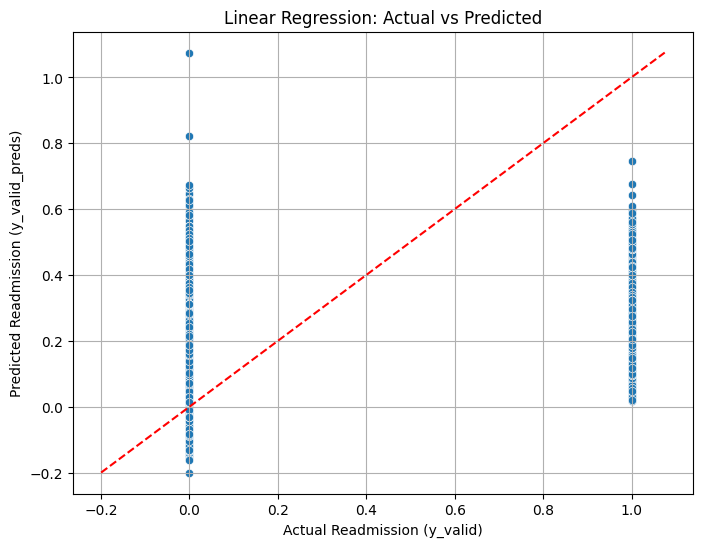

In [234]:
# Create a scatter plot of Actual vs Predicted
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_valid, y=y_valid_preds)

# Add a 45-degree reference line
min_val = min(y_valid.min(), y_valid_preds.min())
max_val = max(y_valid.max(), y_valid_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel("Actual Readmission (y_valid)")
plt.ylabel("Predicted Readmission (y_valid_preds)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


### Logistic Regression

In [235]:
lr=LogisticRegression(random_state = 42, solver = 'newton-cg', max_iter = 200)
lr.fit(X_train, y_train)

y_valid_preds = lr.predict_proba(X_valid)[:,1]

print('Metrics for Validation data:')

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,y_valid_preds, 0.5)

Metrics for Validation data:
AUC:0.663
accuracy:0.878
recall:0.060
precision:0.335
specificity:0.984
prevalence:0.116
 


### KNN Model

In [236]:
knn = KNeighborsClassifier(n_neighbors = 100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:,1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,knn_preds, 0.5)

AUC:0.583
accuracy:0.219
recall:0.927
precision:0.122
specificity:0.117
prevalence:0.116
 


### Stochastic Gradient Descent Model

In [237]:
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgd_preds = sgdc.predict_proba(X_valid)[:, 1]

print('Stochastic Gradient Descent')
print('Validation:')
sgdc_valid_auc, sgdc_valid_accuracy, sgdc_valid_recall, \
sgdc_valid_precision, sgdc_valid_specificity = print_report(y_valid, sgd_preds, 0.5)

Stochastic Gradient Descent
Validation:
AUC:0.590
accuracy:0.376
recall:0.786
precision:0.132
specificity:0.322
prevalence:0.116
 


### Decision Tree

In [238]:
dc_clf = DecisionTreeClassifier(random_state=42, max_depth = 10)
dc_clf.fit(X_train, y_train)

dc_preds_proba = dc_clf.predict_proba(X_valid)[:,1]
dc_preds = dc_clf.predict(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,dc_preds_proba, 0.5)

AUC:0.601
accuracy:0.791
recall:0.211
precision:0.171
specificity:0.863
prevalence:0.116
 


### Random Forest

In [239]:
rf_clf = RandomForestClassifier(random_state=111, max_depth = 3)

rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict(X_valid)
rf_preds_proba = rf_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,rf_preds_proba, 0.5)

AUC:0.564
accuracy:0.245
recall:0.895
precision:0.122
specificity:0.160
prevalence:0.116
 


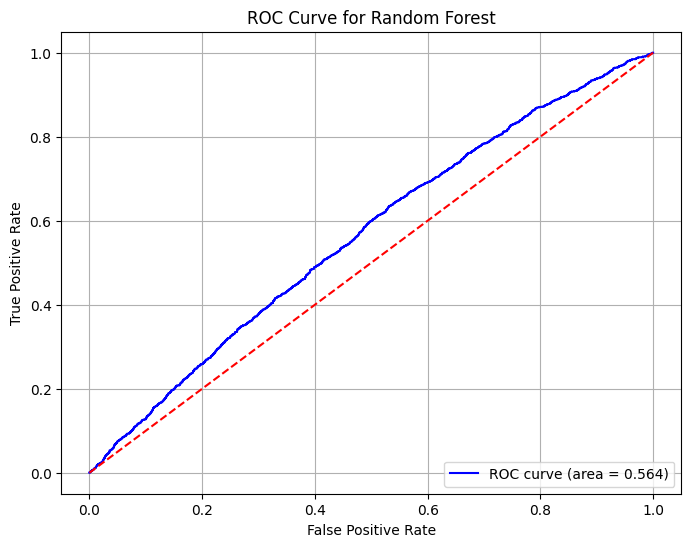

In [240]:
#graph for AUC-ROC curve
from sklearn.metrics import roc_curve, auc  
fpr, tpr, thresholds = roc_curve(y_valid, rf_preds_proba)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='blue', label='ROC curve (area = %.3f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Random Forest')
plt.legend(loc="lower right")
plt.grid()  
plt.show()


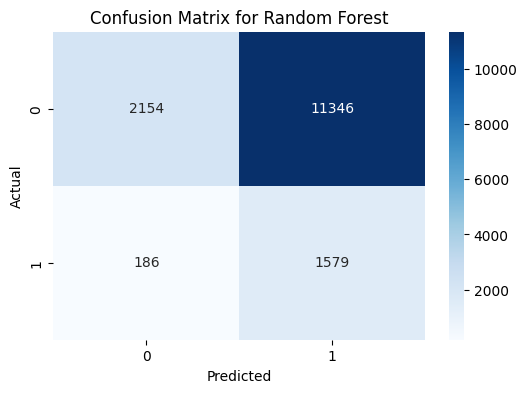

In [241]:
#error log for random forest
from sklearn.metrics import confusion_matrix    
cm = confusion_matrix(y_valid, rf_preds)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Random Forest')
plt.show()


In [242]:
#cross validation for random forest
from sklearn.model_selection import cross_val_score
rf_cv_scores = cross_val_score(rf_clf, X_train, y_train, cv=5, scoring='roc_auc')
print("Random Forest CV AUC Scores:", rf_cv_scores)
print("Random Forest CV AUC Mean:", rf_cv_scores.mean())   

Random Forest CV AUC Scores: [0.70158409 0.94979625 0.95014831 0.94754392 0.94763228]
Random Forest CV AUC Mean: 0.8993409704433253


### Linear SVC

In [114]:
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,lsvc_preds, 0.5)

AUC:0.668
accuracy:0.884
recall:0.006
precision:0.476
specificity:0.999
prevalence:0.116
 


### Gradient Boosting Model

In [115]:
gb_clf = GradientBoostingClassifier(n_estimators = 100, criterion='friedman_mse', learning_rate = 1.0, max_depth = 3,\
                                    random_state = 111)

gb_clf.fit(X_train, y_train)
gb_preds = gb_clf.predict(X_valid)
gb_preds_proba = gb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,gb_preds_proba, 0.5)

AUC:0.647
accuracy:0.865
recall:0.113
precision:0.289
specificity:0.964
prevalence:0.116
 


### XGB Model

In [116]:
xgb_clf = xgb.XGBClassifier(max_depth=3, learning_rate = 1.0, use_label_encoder = False,\
                            eval_metric = 'logloss')
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict(X_valid)
xgb_preds_proba = xgb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,xgb_preds_proba, 0.5)

AUC:0.640
accuracy:0.866
recall:0.115
precision:0.293
specificity:0.964
prevalence:0.116
 


### Catboost Model

In [117]:
catb=CatBoostClassifier(iterations=200, depth=3, learning_rate=1.0, random_state = 111)
catb.fit(X_train, y_train)
catb_preds = catb.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,catb_preds, 0.5)

0:	learn: 0.5432156	total: 150ms	remaining: 29.9s
1:	learn: 0.4847009	total: 157ms	remaining: 15.5s
2:	learn: 0.4495065	total: 162ms	remaining: 10.7s
3:	learn: 0.4205380	total: 169ms	remaining: 8.26s
4:	learn: 0.3818302	total: 174ms	remaining: 6.78s
5:	learn: 0.3612192	total: 179ms	remaining: 5.79s
6:	learn: 0.3465621	total: 184ms	remaining: 5.08s
7:	learn: 0.3344808	total: 189ms	remaining: 4.53s
8:	learn: 0.3207933	total: 194ms	remaining: 4.11s
9:	learn: 0.3070129	total: 200ms	remaining: 3.79s
10:	learn: 0.2965850	total: 205ms	remaining: 3.52s
11:	learn: 0.2893912	total: 210ms	remaining: 3.29s
12:	learn: 0.2826531	total: 217ms	remaining: 3.13s
13:	learn: 0.2736471	total: 222ms	remaining: 2.95s
14:	learn: 0.2676199	total: 227ms	remaining: 2.81s
15:	learn: 0.2622631	total: 233ms	remaining: 2.68s
16:	learn: 0.2576118	total: 239ms	remaining: 2.57s
17:	learn: 0.2513854	total: 244ms	remaining: 2.47s
18:	learn: 0.2467491	total: 250ms	remaining: 2.38s
19:	learn: 0.2429380	total: 255ms	remaini

## Hyper Parameter Tuning

### Decision Tree

In [118]:
# Decision Tree - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

dc_grid = {'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'min_samples_leaf': range(1, 11, 2), ###  -->> Added a critical param
           'criterion':['gini','entropy']} # criterion for evaluating a split

dc_random = RandomizedSearchCV(estimator = dc_clf, param_distributions = dc_grid,
                               n_iter = 20,
                               cv = 10,              ### -->> chnaged cv from 2 to 5
                               scoring ='recall',   ### -->> changed fromscoring=recall_scoring,
                               verbose = 1, random_state = 111)

dc_random.fit(X_train, y_train)

dc_random.best_params_

dc_hp_preds = dc_random.best_estimator_.predict(X_valid)
dc_hp_preds_proba = dc_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, dc_hp_preds_proba)

# added later
print("Best params:", dc_random.best_params_)
print("Best CV recall:", dc_random.best_score_)
print("Validation recall:", recall_score(y_valid, dc_random.best_estimator_.predict(X_valid)))

"""
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
Best CV recall: 0.8327703475995127
Validation recall: 0.996244131455399

add all metrics from above
"""

Fitting 10 folds for each of 20 candidates, totalling 200 fits
Best params: {'min_samples_split': 8, 'min_samples_leaf': 9, 'max_features': 'sqrt', 'max_depth': 3, 'criterion': 'gini'}
Best CV recall: 0.9107434236505124
Validation recall: 0.7898016997167139


"\nFitting 5 folds for each of 20 candidates, totalling 100 fits\nBest params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}\nBest CV recall: 0.8327703475995127\nValidation recall: 0.996244131455399\n\nadd all metrics from above\n"

In [119]:

recall_score(y_valid, dc_hp_preds)

0.7898016997167139

### Random Forest

In [120]:
# Random Forest - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

rf_grid = {'n_estimators':range(200,1000,200), # number of trees
           'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

rf_random = RandomizedSearchCV(estimator = rf_clf, param_distributions = rf_grid,
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

rf_random.fit(X_train, y_train)

rf_random.best_params_

rf_hp_preds = rf_random.best_estimator_.predict(X_valid)
rf_hp_preds_proba = rf_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, rf_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.5644902528590914

In [121]:

recall_score(y_valid, dc_hp_preds)

0.7898016997167139

### XGBoost

In [122]:
#xgboost - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

xgb_grid = params = {
        'min_child_weight': [1, 5, 8, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 0.9, 1.0],
        'max_depth': [3, 4, 5]
        } # criterion for evaluating a split

xgb_random = GridSearchCV(estimator = xgb_clf, param_grid = xgb_grid,
                               cv = 2, scoring = recall_scoring,
                               verbose = 1)

xgb_random.fit(X_train, y_train)

xgb_random.best_params_

xgb_hp_preds = xgb_random.best_estimator_.predict(X_valid)
xgb_hp_preds_proba = xgb_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, xgb_hp_preds_proba)

Fitting 2 folds for each of 720 candidates, totalling 1440 fits


0.6173363970202498

In [123]:

recall_score(y_valid, dc_hp_preds)

0.7898016997167139

#### 4. SAVING PKL MODEL

In [124]:
import joblib
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, accuracy_score, confusion_matrix

# ============================================================
# TARGET
# ============================================================
target = "lessthan30"

print("\n" + "="*70)
print(f"     RANDOM FOREST — FINAL MODEL ({target.upper()}) ")
print("="*70)

prev = y_valid.mean()

# ============================================================
# TRAIN RANDOM FOREST
# ============================================================
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=3,
    min_samples_split=2,
    random_state=111,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# ============================================================
# PREDICT PROBABILITIES
# ============================================================
preds_proba = rf.predict_proba(X_valid)[:, 1]

# ============================================================
# METRICS
# ============================================================
auc = roc_auc_score(y_valid, preds_proba)

preds = (preds_proba >= 0.5).astype(int)

acc = accuracy_score(y_valid, preds)
rec = recall_score(y_valid, preds)
prec = precision_score(y_valid, preds)

tn, fp, fn, tp = confusion_matrix(y_valid, preds).ravel()
spec = tn / (tn + fp)

# ============================================================
# PRINT RESULTS
# ============================================================
print("\nValidation Metrics (Random Forest):")
print("-"*50)
print(f"AUC:          {auc:.4f}")
print(f"Accuracy:     {acc:.4f}")
print(f"Recall:       {rec:.4f}")
print(f"Precision:    {prec:.4f}")
print(f"Specificity:  {spec:.4f}")
print(f"Prevalence:   {prev:.4f}")
print("="*70)

# ============================================================
# SAVE MODEL
# ============================================================
filename = f"{target}_RandomForest_Tuned.Smoteenn.Imputations.pkl"
joblib.dump(rf_random.best_estimator_, filename)

print(f"Saved Tuned Random Forest model as '{filename}'")
print("="*70 + "\n")

final_models = {target: rf_random.best_estimator_}



     RANDOM FOREST — FINAL MODEL (LESSTHAN30) 

Validation Metrics (Random Forest):
--------------------------------------------------
AUC:          0.5664
Accuracy:     0.2572
Recall:       0.8827
Precision:    0.1228
Specificity:  0.1754
Prevalence:   0.1156
Saved Tuned Random Forest model as 'lessthan30_RandomForest_Tuned.Smoteenn.Imputations.pkl'



In [125]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score

def binarize(preds, threshold=0.5):
    return (preds >= threshold).astype(int)

results = []

# Logistic Regression
results.append([
    "Logistic Regression",
    roc_auc_score(y_valid, y_valid_preds),
    accuracy_score(y_valid, binarize(y_valid_preds)),
    recall_score(y_valid, binarize(y_valid_preds)),
    precision_score(y_valid, binarize(y_valid_preds)),
    recall_score(y_valid, binarize(y_valid_preds), pos_label=0)
])

# KNN
results.append([
    "KNN",
    roc_auc_score(y_valid, knn_preds),
    accuracy_score(y_valid, binarize(knn_preds)),
    recall_score(y_valid, binarize(knn_preds)),
    precision_score(y_valid, binarize(knn_preds)),
    recall_score(y_valid, binarize(knn_preds), pos_label=0)
])

# SGDClassifier
results.append([
    "SGDClassifier",
    roc_auc_score(y_valid, sgd_preds),
    accuracy_score(y_valid, binarize(sgd_preds)),
    recall_score(y_valid, binarize(sgd_preds)),
    precision_score(y_valid, binarize(sgd_preds)),
    recall_score(y_valid, binarize(sgd_preds), pos_label=0)
])

# Decision Tree
results.append([
    "Decision Tree",
    roc_auc_score(y_valid, dc_preds_proba),
    accuracy_score(y_valid, dc_preds),
    recall_score(y_valid, dc_preds),
    precision_score(y_valid, dc_preds),
    recall_score(y_valid, dc_preds, pos_label=0)
])

# Random Forest
results.append([
    "Random Forest",
    roc_auc_score(y_valid, rf_preds_proba),
    accuracy_score(y_valid, rf_preds),
    recall_score(y_valid, rf_preds),
    precision_score(y_valid, rf_preds),
    recall_score(y_valid, rf_preds, pos_label=0)
])

# Linear SVC
results.append([
    "Linear SVC",
    roc_auc_score(y_valid, lsvc_preds),
    accuracy_score(y_valid, binarize(lsvc_preds, threshold=0)),
    recall_score(y_valid, binarize(lsvc_preds, threshold=0)),
    precision_score(y_valid, binarize(lsvc_preds, threshold=0)),
    recall_score(y_valid, binarize(lsvc_preds, threshold=0), pos_label=0)
])

# Gradient Boosting
results.append([
    "Gradient Boosting",
    roc_auc_score(y_valid, gb_preds_proba),
    accuracy_score(y_valid, gb_preds),
    recall_score(y_valid, gb_preds),
    precision_score(y_valid, gb_preds),
    recall_score(y_valid, gb_preds, pos_label=0)
])

# XGBoost
results.append([
    "XGBoost",
    roc_auc_score(y_valid, xgb_preds_proba),
    accuracy_score(y_valid, xgb_preds),
    recall_score(y_valid, xgb_preds),
    precision_score(y_valid, xgb_preds),
    recall_score(y_valid, xgb_preds, pos_label=0)
])

# CatBoost
results.append([
    "CatBoost",
    roc_auc_score(y_valid, catb_preds),
    accuracy_score(y_valid, binarize(catb_preds)),
    recall_score(y_valid, binarize(catb_preds)),
    precision_score(y_valid, binarize(catb_preds)),
    recall_score(y_valid, binarize(catb_preds), pos_label=0)
])

# Decision Tree (HP Tuned)
results.append([
    "Decision Tree (HP Tuned)",
    roc_auc_score(y_valid, dc_hp_preds_proba),
    accuracy_score(y_valid, dc_hp_preds),
    recall_score(y_valid, dc_hp_preds),
    precision_score(y_valid, dc_hp_preds),
    recall_score(y_valid, dc_hp_preds, pos_label=0)
])

# Random Forest (HP Tuned)
results.append([
    "Random Forest (HP Tuned)",
    roc_auc_score(y_valid, rf_hp_preds_proba),
    accuracy_score(y_valid, rf_hp_preds),
    recall_score(y_valid, rf_hp_preds),
    precision_score(y_valid, rf_hp_preds),
    recall_score(y_valid, rf_hp_preds, pos_label=0)
])

# XGBoost (HP Tuned)
results.append([
    "XGBoost (HP Tuned)",
    roc_auc_score(y_valid, xgb_hp_preds_proba),
    accuracy_score(y_valid, xgb_hp_preds),
    recall_score(y_valid, xgb_hp_preds),
    precision_score(y_valid, xgb_hp_preds),
    recall_score(y_valid, xgb_hp_preds, pos_label=0)
])

results_df = pd.DataFrame(results, columns=["Model", "ROC-AUC", "Accuracy", "Recall", "Precision", "Specificity"])
results_df


,Model,ROC-AUC,Accuracy,Recall,Precision,Specificity
0,Logistic Regression,0.665520,0.879332,0.058924,0.364912,0.986593
1,KNN,0.580742,0.216246,0.926912,0.121446,0.123333
2,SGDClassifier,0.596633,0.448739,0.708215,0.136612,0.414815
3,Decision Tree,0.581884,0.785064,0.201700,0.159785,0.861333
4,Random Forest,0.566407,0.257190,0.882720,0.122774,0.175407
5,Linear SVC,0.668318,0.880904,0.047592,0.380090,0.989852
6,Gradient Boosting,0.646835,0.865313,0.113314,0.289436,0.963630
7,XGBoost,0.640255,0.865509,0.115014,0.292507,0.963630
8,CatBoost,0.652887,0.866295,0.116147,0.298834,0.964370
9,Decision Tree (HP Tuned),0.511469,0.286734,0.789802,0.117035,0.220963


SHAP Explainability Analysis — FIXED

Using 100 samples for SHAP analysis

1. RANDOM FOREST SHAP
----------------------------------------------------------------------


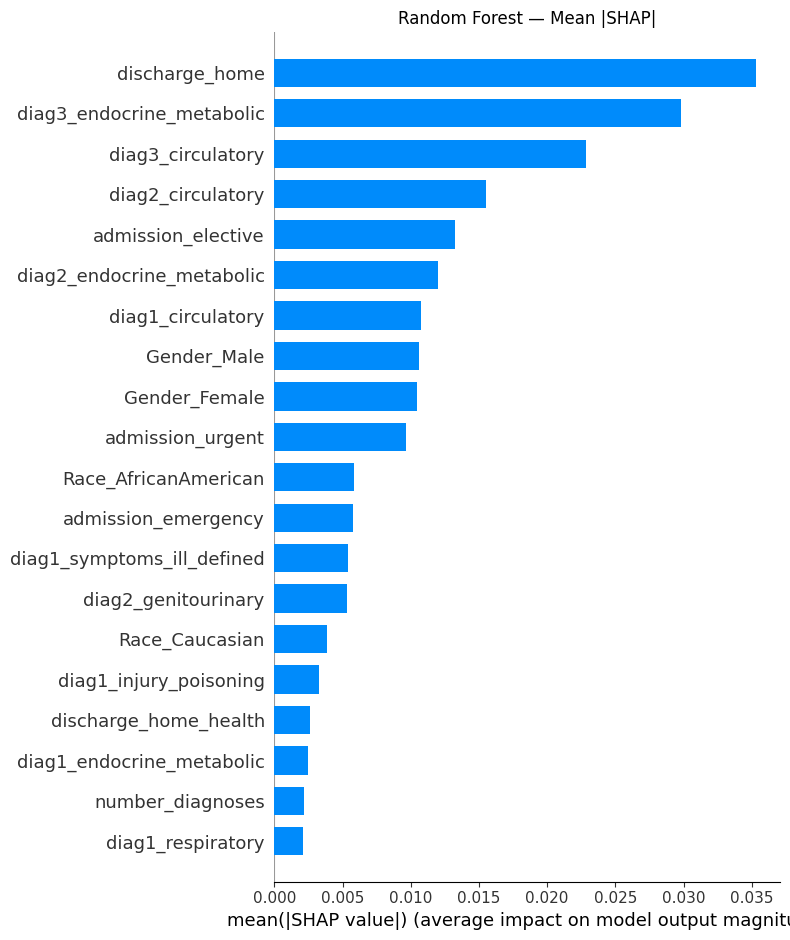

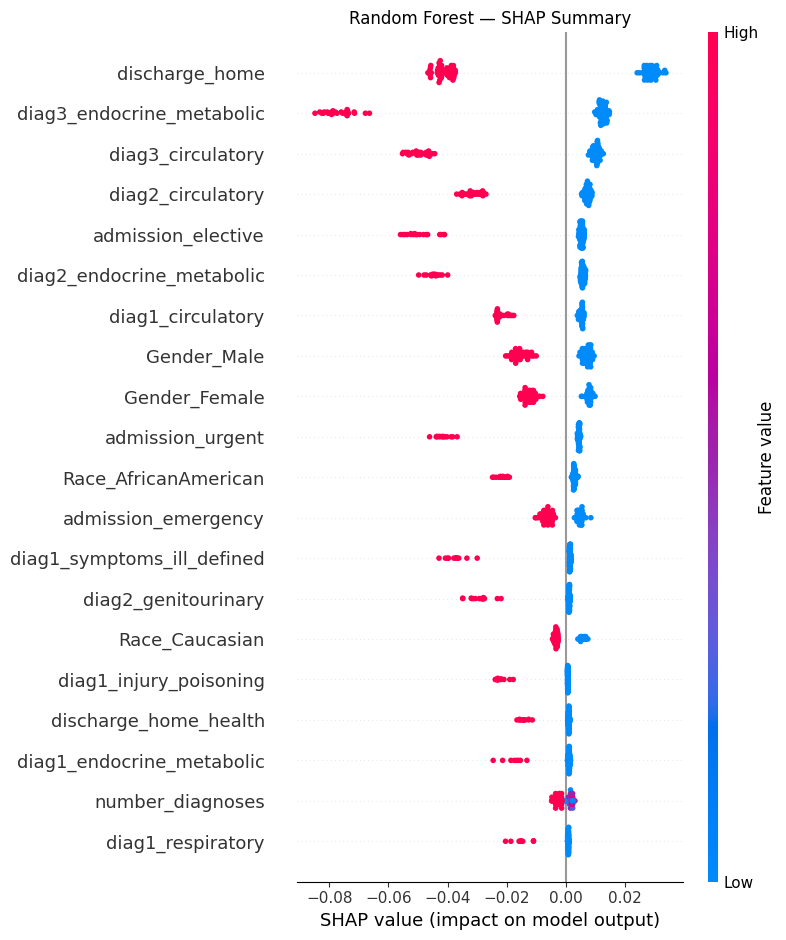

2. XGBOOST SHAP
----------------------------------------------------------------------


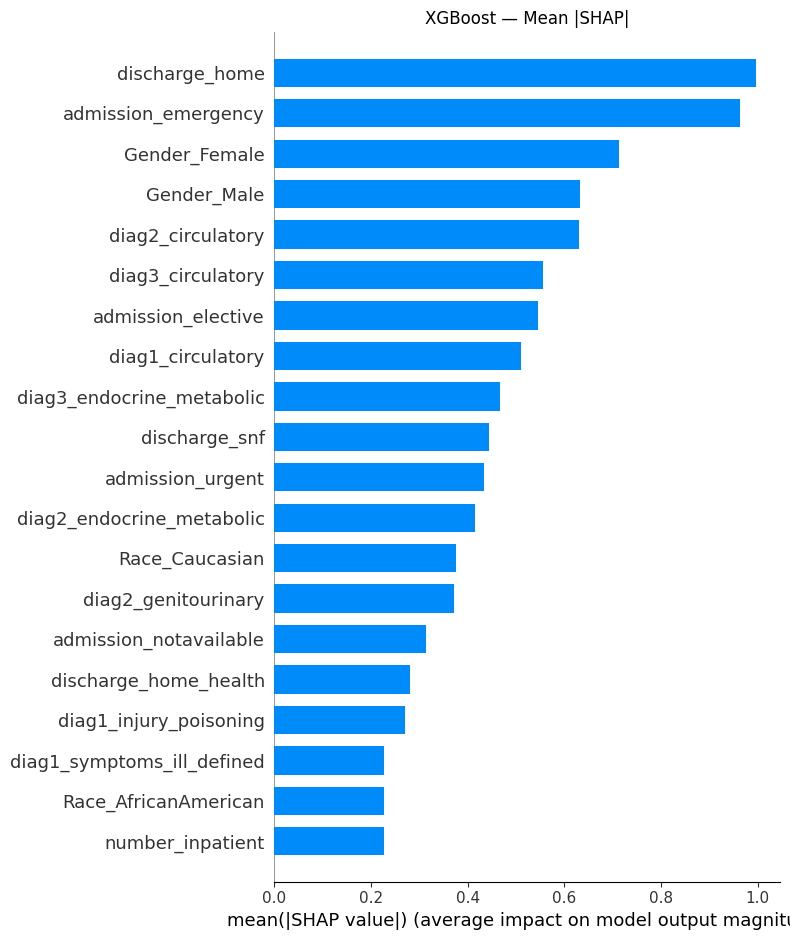

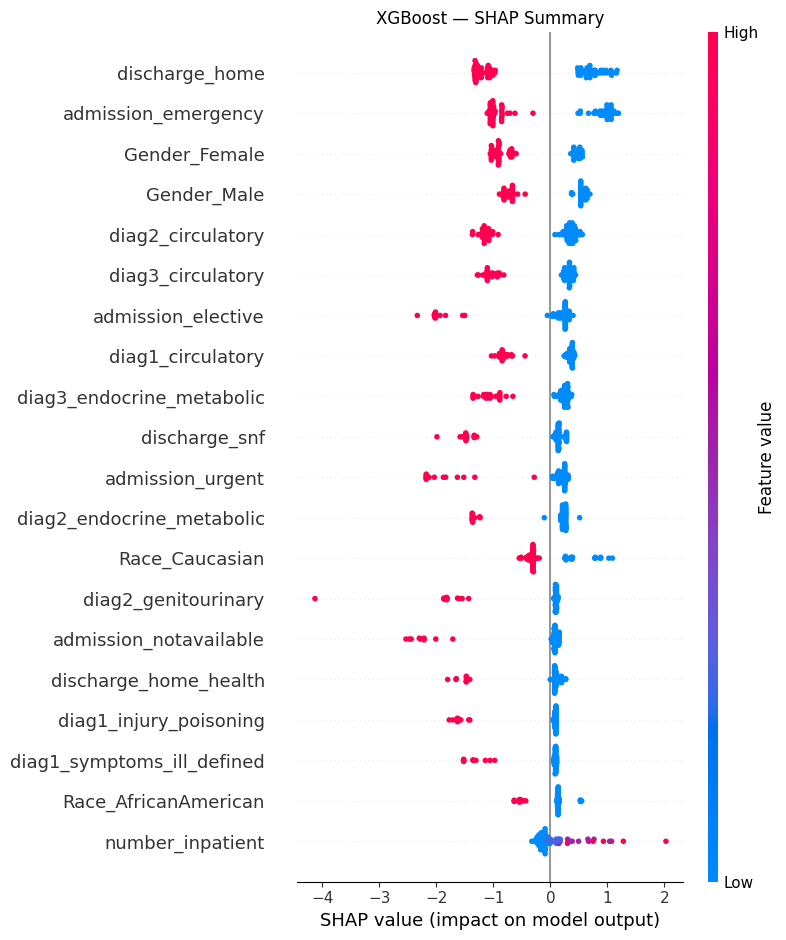

3. CATBOOST SHAP
----------------------------------------------------------------------


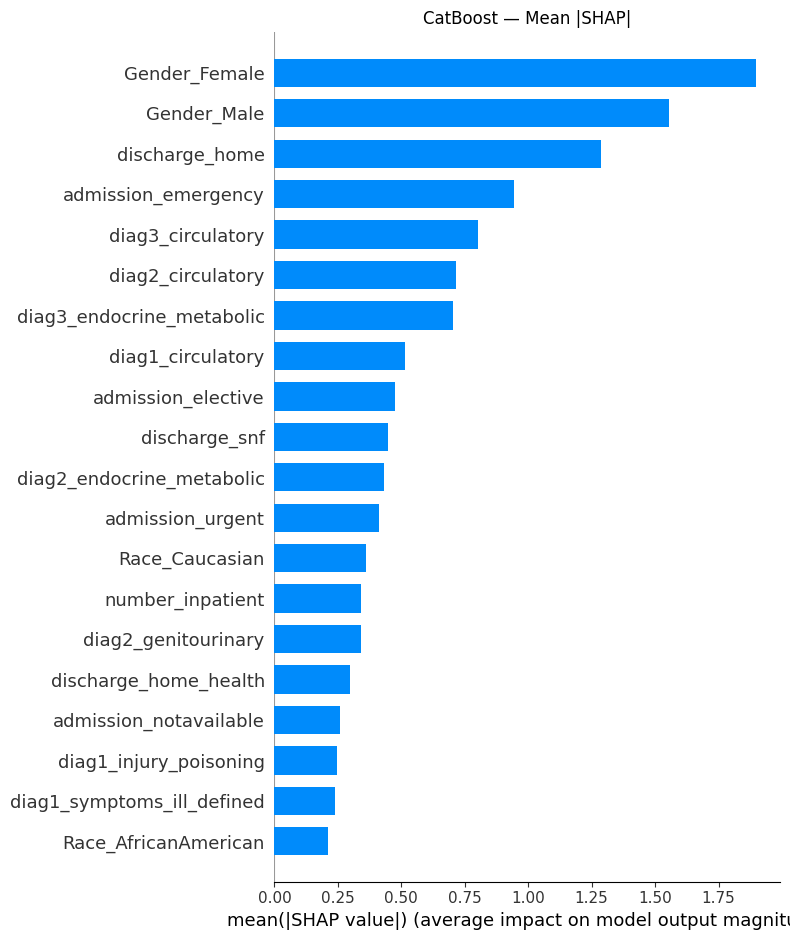

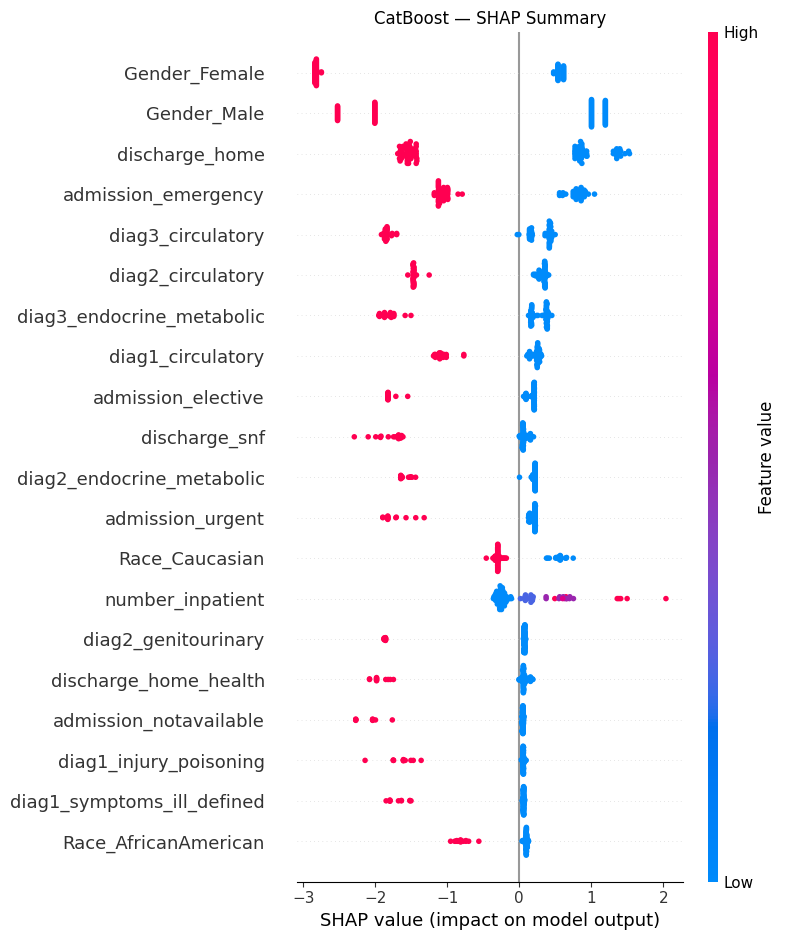

4. FORCE PLOT
----------------------------------------------------------------------


✓ Force plot saved as rf_force_plot_sample1.html

5. DEPENDENCE PLOTS
----------------------------------------------------------------------


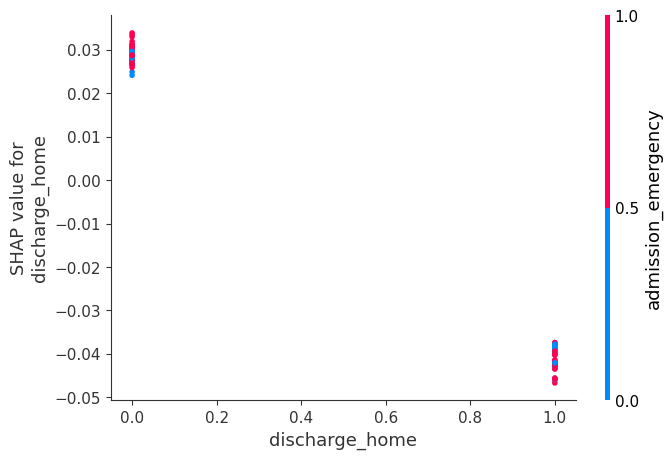

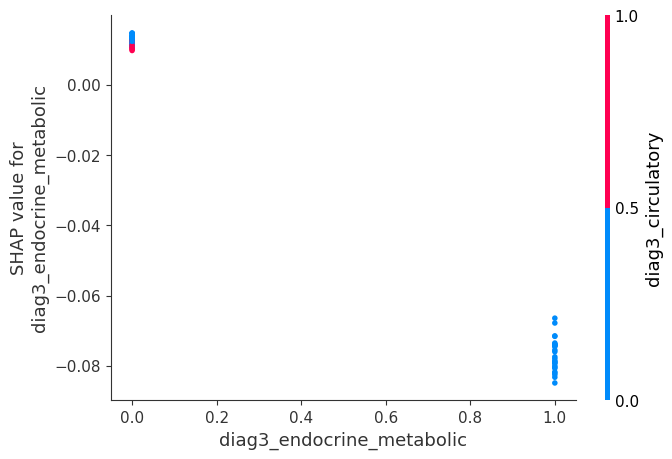

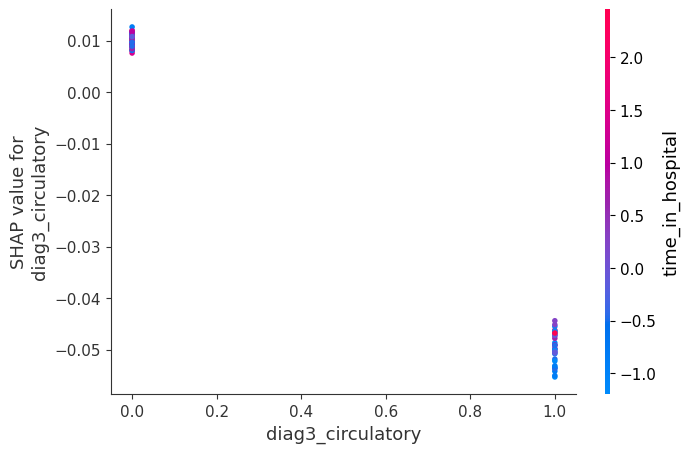

6. FEATURE IMPORTANCE COMPARISON
----------------------------------------------------------------------
                  Feature       RF      XGB     CATB
           discharge_home 0.035308 0.996634 1.285343
diag3_endocrine_metabolic 0.029834 0.467164 0.703333
        diag3_circulatory 0.022813 0.555898 0.800942
        diag2_circulatory 0.015534 0.630277 0.715624
       admission_elective 0.013246 0.545145 0.475243
diag2_endocrine_metabolic 0.011980 0.415985 0.432166
        diag1_circulatory 0.010745 0.509485 0.514135
              Gender_Male 0.010599 0.632382 1.556202
            Gender_Female 0.010425 0.713338 1.897399
         admission_urgent 0.009634 0.434554 0.412168


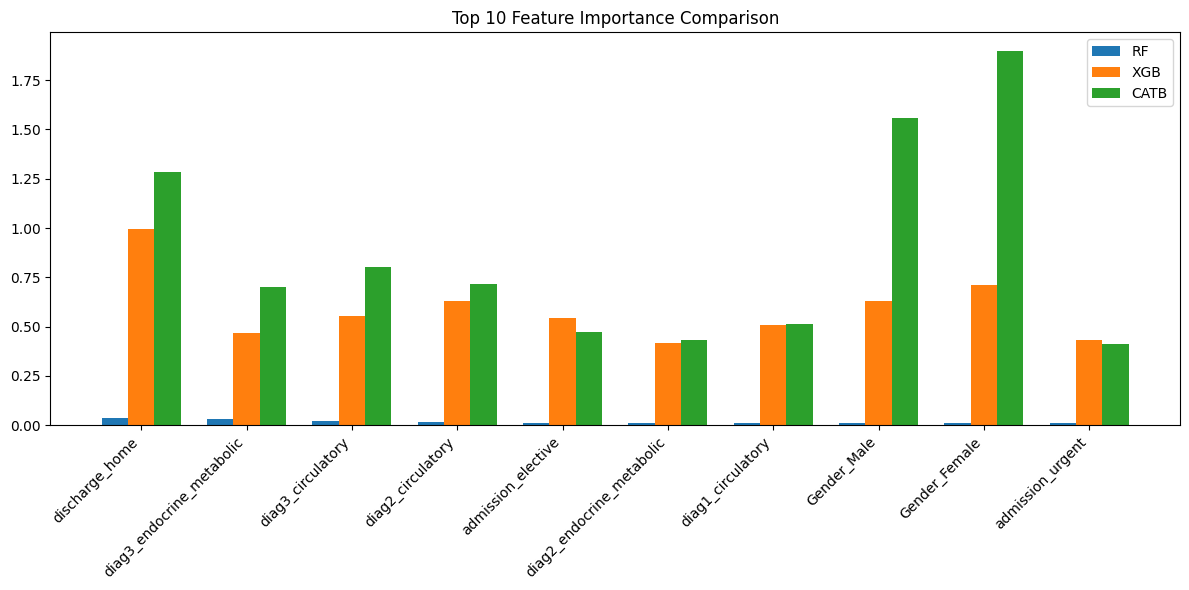

7. SUMMARY
----------------------------------------------------------------------
RF Mean |SHAP|: 0.0020
XGB Mean |SHAP|: 0.1313
CATB Mean |SHAP|: 0.1552
SHAP analysis complete!


In [126]:
import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("=" * 70)
print("SHAP Explainability Analysis — FIXED")
print("=" * 70 + "\n")

# ============================================================
# 0. ENSURE ALL MODELS USE IDENTICAL FEATURES
# ============================================================
X_sample = X_valid[X_train.columns].iloc[:100].copy()
y_sample = y_valid.iloc[:100]

print(f"Using {len(X_sample)} samples for SHAP analysis\n")

# ============================================================
# Helper: Force SHAP values into correct 2D shape
# ============================================================
def get_shap_matrix(explainer, X):
    shap_vals = explainer.shap_values(X)

    # Binary classifier → list of arrays
    if isinstance(shap_vals, list):
        shap_vals = shap_vals[1] if len(shap_vals) > 1 else shap_vals[0]

    shap_vals = np.asarray(shap_vals, dtype=float)

    # If 1D → reshape to (1, n_features)
    if shap_vals.ndim == 1:
        shap_vals = shap_vals.reshape(1, -1)

    return shap_vals


# ============================================================
# 1. RANDOM FOREST SHAP (FIXED FOR 3D OUTPUT)
# ============================================================
print("1. RANDOM FOREST SHAP")
print("-" * 70)

explainer_rf = shap.TreeExplainer(rf_clf)
shap_values_rf = explainer_rf.shap_values(X_sample)

# FIX: RandomForest returns (samples, features, classes)
# Reduce to class 1 (positive class)
if shap_values_rf.ndim == 3:
    shap_values_rf = shap_values_rf[:, :, 1]

shap_values_rf = np.asarray(shap_values_rf, dtype=float)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_rf, X_sample, plot_type="bar", show=False)
plt.title("Random Forest — Mean |SHAP|")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_rf, X_sample, show=False)
plt.title("Random Forest — SHAP Summary")
plt.tight_layout()
plt.show()


# ============================================================
# 2. XGBOOST SHAP
# ============================================================
print("2. XGBOOST SHAP")
print("-" * 70)

explainer_xgb = shap.TreeExplainer(xgb_clf)
shap_values_xgb = get_shap_matrix(explainer_xgb, X_sample)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_xgb, X_sample, plot_type="bar", show=False)
plt.title("XGBoost — Mean |SHAP|")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_xgb, X_sample, show=False)
plt.title("XGBoost — SHAP Summary")
plt.tight_layout()
plt.show()


# ============================================================
# 3. CATBOOST SHAP
# ============================================================
print("3. CATBOOST SHAP")
print("-" * 70)

explainer_catb = shap.TreeExplainer(catb)
shap_values_catb = get_shap_matrix(explainer_catb, X_sample)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_catb, X_sample, plot_type="bar", show=False)
plt.title("CatBoost — Mean |SHAP|")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_catb, X_sample, show=False)
plt.title("CatBoost — SHAP Summary")
plt.tight_layout()
plt.show()


# ============================================================
# 4. FORCE PLOT (FIXED)
# ============================================================
print("4. FORCE PLOT")
print("-" * 70)

shap.initjs()

force_plot = shap.force_plot(
    explainer_rf.expected_value[1],
    shap_values_rf[0],      # 1D vector
    X_sample.iloc[0]        # 1D feature row
)

shap.save_html("rf_force_plot_sample1.html", force_plot)
print("✓ Force plot saved as rf_force_plot_sample1.html\n")


# ============================================================
# 5. DEPENDENCE PLOTS (FIXED)
# ============================================================
print("5. DEPENDENCE PLOTS")
print("-" * 70)

feature_importance = np.abs(shap_values_rf).mean(axis=0)
top_idx = np.argsort(feature_importance)[-5:][::-1]

for idx in top_idx[:3]:
    shap.dependence_plot(
        idx,
        shap_values_rf,
        X_sample,
        feature_names=X_sample.columns
    )


# ============================================================
# 6. FEATURE IMPORTANCE COMPARISON (FIXED)
# ============================================================
print("6. FEATURE IMPORTANCE COMPARISON")
print("-" * 70)

df_compare = pd.DataFrame({
    "Feature": X_sample.columns,
    "RF": np.abs(shap_values_rf).mean(axis=0),
    "XGB": np.abs(shap_values_xgb).mean(axis=0),
    "CATB": np.abs(shap_values_catb).mean(axis=0)
})

df_top10 = df_compare.sort_values("RF", ascending=False).head(10)
print(df_top10.to_string(index=False))

plt.figure(figsize=(12, 6))
x = np.arange(len(df_top10))
width = 0.25

plt.bar(x - width, df_top10["RF"], width, label="RF")
plt.bar(x, df_top10["XGB"], width, label="XGB")
plt.bar(x + width, df_top10["CATB"], width, label="CATB")

plt.xticks(x, df_top10["Feature"], rotation=45, ha="right")
plt.title("Top 10 Feature Importance Comparison")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 7. SUMMARY
# ============================================================
print("7. SUMMARY")
print("-" * 70)

print(f"RF Mean |SHAP|: {np.abs(shap_values_rf).mean():.4f}")
print(f"XGB Mean |SHAP|: {np.abs(shap_values_xgb).mean():.4f}")
print(f"CATB Mean |SHAP|: {np.abs(shap_values_catb).mean():.4f}")

print("=" * 70)
print("SHAP analysis complete!")
print("=" * 70)
